In [1]:
import pandas as pd

inputs = pd.read_csv('/Users/mx23826/Documents/ML_winter_school/BoFlex/SDL Case Studies/Inorganic Nanomaterials/Case2_MHP NCs/Dataset/inputs.csv')
outputs = pd.read_csv('/Users/mx23826/Documents/ML_winter_school/BoFlex/SDL Case Studies/Inorganic Nanomaterials/Case2_MHP NCs/Dataset/outputs.csv')

In [2]:
inputs

,QD,ZnI2,ZnBr2,OA,OLA
0,1.000000,0.000000,0.000000,1.000000,0.000000
1,1.000000,1.000000,1.000000,0.000000,1.000000
2,0.500000,0.500000,0.500000,0.500000,0.500000
3,0.500000,0.500000,0.500000,0.500000,0.500000
4,0.500000,0.500000,0.000000,0.500000,0.000000
...,...,...,...,...,...
1294,0.547186,0.637242,0.372737,0.639060,0.963832
1295,0.408661,0.881985,0.044452,0.448528,0.712489
1296,0.463988,0.798886,0.100168,0.606947,0.723723
1297,0.462418,0.860659,0.083278,0.653757,0.896948


/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/umap/umap_.py:3024: UserWarning: gradient function is not yet implemented for jaccard di

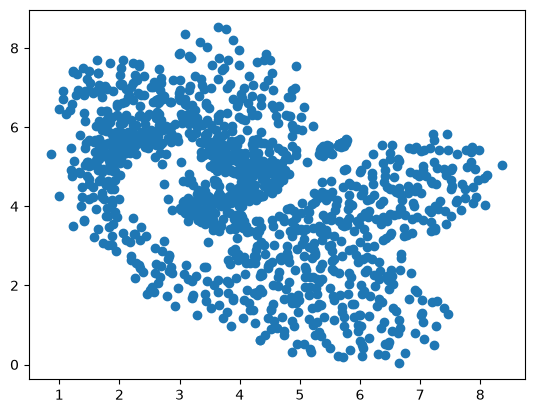

In [3]:
from sklearn.decomposition import PCA
from umap import UMAP

# reducer = PCA(n_components=2)
reducer = UMAP(n_components=2, random_state=42, metric='jaccard')

data = reducer.fit_transform(inputs)

import matplotlib.pyplot as plt

plt.scatter(data[:, 0], data[:, 1], )

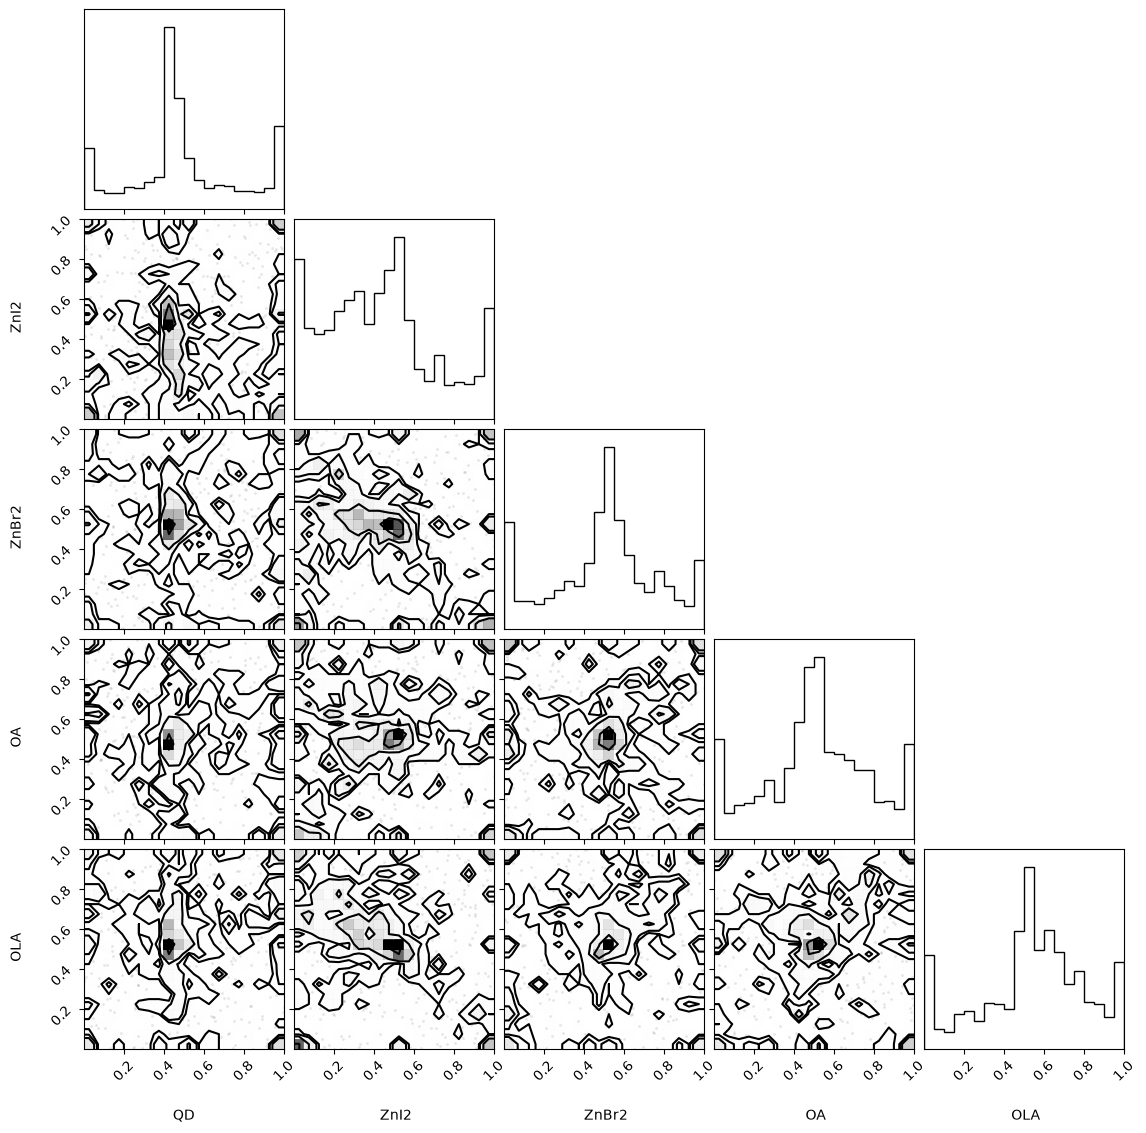

In [4]:
import corner

fig = corner.corner(inputs, labels=inputs.columns)

In [5]:
# Data is uncorrelated, so cannot use simple regression. Must use BO!

In [6]:
from sklearn.model_selection import train_test_split
import torch

total = pd.concat([inputs, outputs], axis=1)
train, test = train_test_split(total, test_size=0.1, random_state=42)

train_X=train.iloc[:, :inputs.shape[1]]
train_Y=train.iloc[:, -outputs.shape[1]:]
test_X=test.iloc[:, :inputs.shape[1]]
test_Y=test.iloc[:, -outputs.shape[1]:]

train_X = torch.tensor(train_X.values)
train_Y = torch.tensor(train_Y.values)
test_X = torch.tensor(test_X.values)
test_Y = torch.tensor(test_Y.values)

In [ ]:
# Following this tutorial for MOBO with botorch: https://jonathan-guerne.medium.com/multi-objective-bayesian-optimization-with-botorch-3c5cf348c63b
# And the GP_BO_Exercises notebook

from botorch.models import SingleTaskGP, ModelListGP
from gpytorch.mlls import ExactMarginalLogLikelihood, SumMarginalLogLikelihood
from botorch.fit import fit_gpytorch_mll
from botorch.acquisition import UpperConfidenceBound

models = []
for i in range(outputs.shape[1]):
    model = SingleTaskGP(train_X, train_Y[:, i].unsqueeze(1))
    models.append(model)
    
gp = ModelListGP(*models)
mll = SumMarginalLogLikelihood(gp.likelihood, gp)
fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood,model))
acq=UpperConfidenceBound(model=model,beta=2.0**2)

ExactMarginalLogLikelihood(
  (likelihood): GaussianLikelihood(
    (noise_covar): HomoskedasticNoise(
      (noise_prior): LogNormalPrior()
      (raw_noise_constraint): GreaterThan(1.000E-04)
    )
  )
  (model): SingleTaskGP(
    (likelihood): GaussianLikelihood(
      (noise_covar): HomoskedasticNoise(
        (noise_prior): LogNormalPrior()
        (raw_noise_constraint): GreaterThan(1.000E-04)
      )
    )
    (mean_module): ConstantMean()
    (covar_module): RBFKernel(
      (lengthscale_prior): LogNormalPrior()
      (raw_lengthscale_constraint): GreaterThan(2.500E-02)
    )
    (outcome_transform): Standardize()
  )
)